# Topic extraction analysis: eacr-2026

Looks only at `title` and `topics` from `data/topics/eacr-2026.jsonl` (step 3 output). 

In [1]:
import json
import os
from collections import Counter
from pathlib import Path

import httpx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv
from matplotlib.colors import LinearSegmentedColormap
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize

NAME = "eacr-2026"
ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()
)
load_dotenv(ROOT / ".env")
OLLAMA_URL = os.environ.get("OLLAMA_URL") or "http://localhost:11434/v1"
EMBED_MODEL = (
    os.environ.get("EMBED_MODEL")
    or "hf.co/dontia/embeddinggemma-300m-medical-Q8_0-GGUF:Q8_0"
)
# Task prefix is model specific; for nomic-embed-text use "clustering: "
EMBED_PREFIX = os.environ.get("EMBED_PREFIX") or "task: clustering | query: "
PLOT_DIR = ROOT / "data" / "plots" / "step4"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

SURFACE, INK, SECONDARY, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
BLUE, NEUTRAL = "#2a78d6", "#c3c2b7"
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)

sns.set_theme(
    style="whitegrid",
    context="notebook",
    rc={
        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
        "font.size": 11,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 12,
        "axes.labelsize": 11,
        "axes.labelcolor": SECONDARY,
        "xtick.labelsize": 10.5,
        "ytick.labelsize": 11,
        "xtick.color": MUTED,
        "ytick.color": INK,
        "text.color": INK,
        "axes.edgecolor": NEUTRAL,
        "grid.color": "#e1e0d9",
        "legend.fontsize": 10.5,
        "legend.frameon": False,
        "figure.dpi": 110,
        "savefig.dpi": 200,
    },
)


def finish(fig, name):
    sns.despine(fig=fig, left=True)
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"{name}.png", bbox_inches="tight", facecolor=SURFACE)
    plt.show()


def short(title, n=45):
    return title if len(title) <= n else title[: n - 1] + "…"


lines = (
    (ROOT / "data" / "topics" / f"{NAME}.jsonl")
    .read_text(encoding="utf-8")
    .splitlines()
)
df = pd.DataFrame([json.loads(line) for line in lines if line.strip()])[
    ["title", "topics"]
]
df["title"] = df["title"].str.strip("[]")
with_topics = df[df["topics"].notna()].reset_index(drop=True)

print(f"{NAME}: {len(df)} titles, {len(with_topics)} with topics")
print("Embedding model:", EMBED_MODEL)
print("Saving plots to", PLOT_DIR)

eacr-2026: 38 titles, 7 with topics
Embedding model: hf.co/dontia/embeddinggemma-300m-medical-Q8_0-GGUF:Q8_0
Saving plots to /Users/emlacic/test/recsys/ecc1/data/plots/step4


## 1. Topic frequency and normalization

Topics are normalized (lowercase, British to American spelling, stopwords dropped) and split into words. Whole phrases rarely repeat across records, so the counts are per word: the number of records whose topics contain it.

44 topics, 44 unique phrases, 93 unique words (8 in 2+ records)
Normalization changed 2 topics


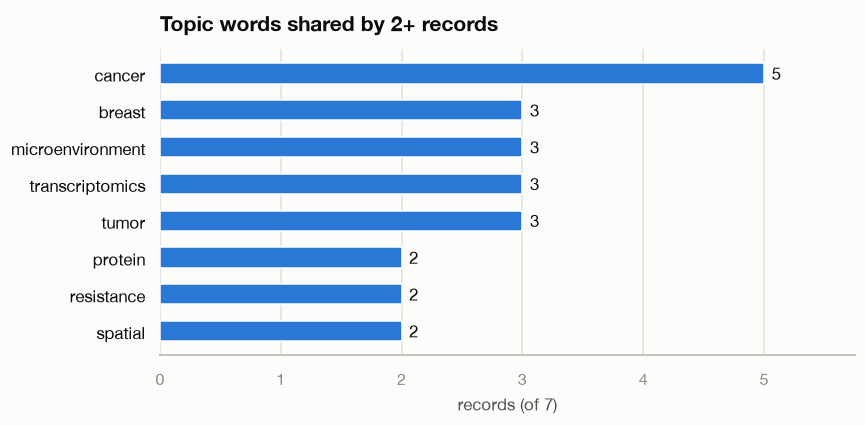

In [2]:
SPELLING = {"tumour": "tumor", "tumours": "tumors"}
STOPWORDS = {"a", "an", "and", "for", "in", "of", "on", "the", "to", "with"}


def normalize_topic(topic):
    return " ".join(SPELLING.get(w, w) for w in topic.lower().split())


def words(topic):
    return [w for w in normalize_topic(topic).split() if w not in STOPWORDS]


exploded = (
    with_topics["topics"].explode().rename("raw").rename_axis("record").reset_index()
)
exploded["topic"] = exploded["raw"].map(normalize_topic)
record_words = exploded.groupby("record")["topic"].agg(
    lambda s: sorted({w for t in s for w in words(t)})
)
doc_freq = Counter(w for ws in record_words for w in ws)
shared_words = sorted(
    ((w, n) for w, n in doc_freq.items() if n > 1), key=lambda kv: (-kv[1], kv[0])
)

print(
    f"{len(exploded)} topics, {exploded['topic'].nunique()} unique phrases, "
    f"{len(doc_freq)} unique words ({len(shared_words)} in 2+ records)"
)
print(f"Normalization changed {(exploded['raw'] != exploded['topic']).sum()} topics")

labels, values = zip(*shared_words)
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(labels, values, color=BLUE, height=0.55)
ax.bar_label(ax.containers[0], padding=5, fontsize=11)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set(
    xlim=(0, max(values) * 1.15),
    xlabel=f"records (of {len(with_topics)})",
    ylabel="",
    title="Topic words shared by 2+ records",
)

finish(fig, "01_topic_words")

## 2. Word co-occurrence

Number of records in which two of the shared words both appear. The diagonal is the word's own record count.

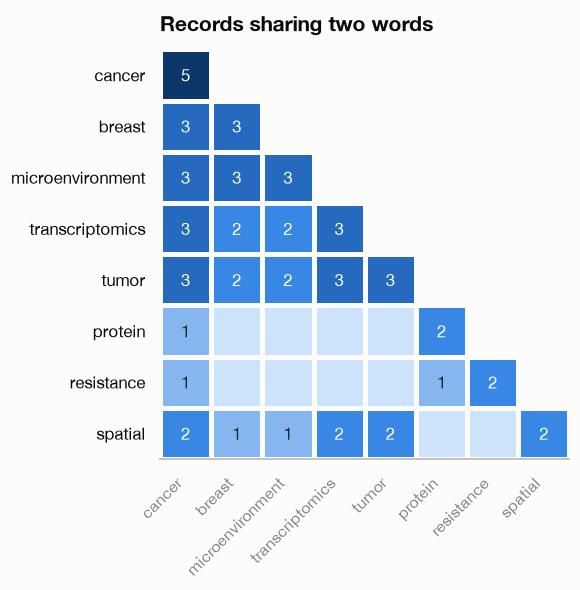

In [3]:
def triangle_heatmap(values, spec, xlabels, ylabels, title, name, figsize, xrot=0):
    # Show the lower triangle with the diagonal; blank out zero cells
    annot = np.where(values > 0, np.char.mod(spec, values), "")
    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(
        values,
        mask=np.triu(np.ones(values.shape, bool), k=1),
        annot=annot,
        fmt="",
        cmap=SEQUENTIAL,
        vmin=0,
        linewidths=2,
        linecolor=SURFACE,
        cbar=False,
        square=True,
        xticklabels=xlabels,
        yticklabels=ylabels,
        ax=ax,
    )
    ax.grid(False)
    plt.setp(ax.get_xticklabels(), rotation=xrot, ha="right" if xrot else "center")
    plt.setp(ax.get_yticklabels(), rotation=0)
    ax.set(title=title)
    finish(fig, name)


top = [w for w, _ in shared_words]
presence = np.array([[w in ws for w in top] for ws in record_words], dtype=int)
triangle_heatmap(
    presence.T @ presence,
    "%d",
    top,
    top,
    "Records sharing two words",
    "02_cooccurrence",
    figsize=(6, 5.5),
    xrot=45,
)

## 3. Record similarity

Cosine similarity between records, using TF-IDF over their normalized topic words. Words shared by many records count less than rare ones. Each pair appears once (the diagonal is always 1 and left out).

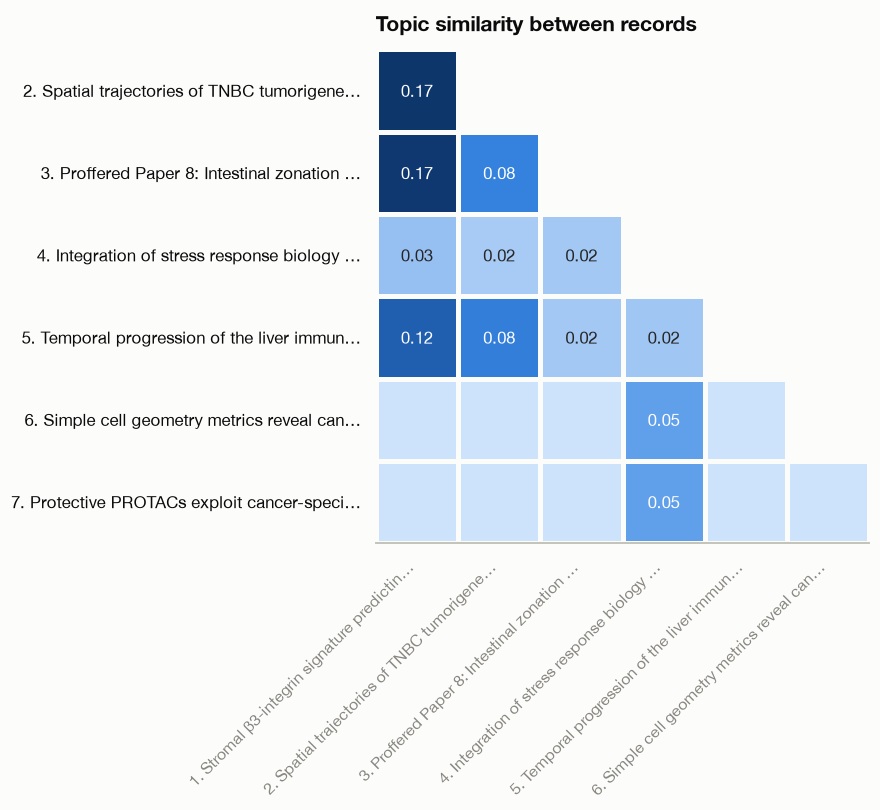

In [4]:
tfidf = TfidfVectorizer(token_pattern=r"\S+").fit_transform(record_words.map(" ".join))
numbered = [f"{i + 1}. {short(t, 40)}" for i, t in enumerate(with_topics["title"])]
triangle_heatmap(
    (tfidf @ tfidf.T).toarray()[1:, :-1],
    "%.2f",
    numbered[:-1],
    numbered[1:],
    "Topic similarity between records",
    "03_record_similarity",
    figsize=(9, 7.5),
    xrot=45,
)

## Clustering

The Ollama model set in the setup cell turns each text into a vector (an embedding), and k-means groups texts whose vectors are close.

Before clustering, the mean vector of all texts is subtracted from every embedding (centering). All texts are about cancer, so their embeddings point in a similar direction, and this shared part says nothing about how one text differs from another. Removing it leaves the differences from the average text, which is what k-means should split on.

Clusters are drawn on the first two principal components (a 2D projection of the vectors), and each cluster is named by its top TF-IDF terms, the words most typical of its texts.

`K` is fixed at 3 so the scatter stays readable with three colors (each cluster also has its own marker shape); it is not chosen by score. The silhouette panel shows how well separated the clusters are for other values of k.

In [5]:
K = 3
CLUSTER_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
CLUSTER_MARKERS = ["o", "s", "^"]


def embed_centered(texts):
    resp = httpx.post(
        f"{OLLAMA_URL}/embeddings",
        json={"model": EMBED_MODEL, "input": [f"{EMBED_PREFIX}{t}" for t in texts]},
        timeout=120,
    )
    resp.raise_for_status()
    x = normalize(np.array([d["embedding"] for d in resp.json()["data"]]))
    return normalize(x - x.mean(axis=0))


def kmeans(x, k):
    return KMeans(k, n_init=20, random_state=0).fit_predict(x)


def top_terms(texts, labels, n=3):
    vec = TfidfVectorizer(stop_words="english", sublinear_tf=True)
    tfidf = vec.fit_transform(texts)
    terms = vec.get_feature_names_out()
    means = [np.asarray(tfidf[labels == c].mean(axis=0)).ravel() for c in range(K)]
    return [", ".join(terms[m.argsort()[::-1][:n]]) for m in means]


def cluster_report(titles, texts, ks, heading, name, number_points=False):
    x = embed_centered(texts)
    labels = kmeans(x, K)
    coords = PCA(2, random_state=0).fit_transform(x)
    terms = top_terms(texts, labels)
    scores = pd.Series({k: silhouette_score(x, kmeans(x, k)) for k in ks})

    fig, (ax1, ax2) = plt.subplots(
        1, 2, figsize=(13, 5.4), gridspec_kw={"width_ratios": [1.7, 1]}
    )
    for c in range(K):
        pts = coords[labels == c]
        ax1.scatter(
            *pts.T,
            s=80,
            color=CLUSTER_COLORS[c],
            marker=CLUSTER_MARKERS[c],
            edgecolor=SURFACE,
            linewidth=1.5,
            label=f"{c + 1}: {terms[c]} (n={len(pts)})",
        )
    if number_points:
        for i, (px, py) in enumerate(coords):
            ax1.annotate(
                str(i + 1),
                (px, py),
                xytext=(7, 5),
                textcoords="offset points",
                fontsize=10,
                color=SECONDARY,
            )
    ax1.grid(False)
    ax1.set(xticks=[], yticks=[], xlabel="PCA 1", ylabel="PCA 2", title=heading)
    ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08))

    ax2.bar(
        scores.index.astype(str),
        scores.values,
        color=[BLUE if k == K else NEUTRAL for k in scores.index],
        width=0.55,
    )
    ax2.bar_label(ax2.containers[0], fmt="%.3f", padding=3, fontsize=10)
    ax2.grid(axis="x", visible=False)
    ax2.set(
        ylim=(min(0, scores.min() * 1.2), max(scores.max() * 1.2, 0.1)),
        xlabel="number of clusters k",
        ylabel="",
        title="Silhouette (higher is better)",
    )
    finish(fig, name)

    for c in range(K):
        print(f"Cluster {c + 1} ({terms[c]}):")
        for i in np.flatnonzero(labels == c):
            print(f"  {i + 1:>2}. {short(titles[i], 100)}")

## 4. Clusters of titles (all records)

Title only, so every record takes part, including those without topics.

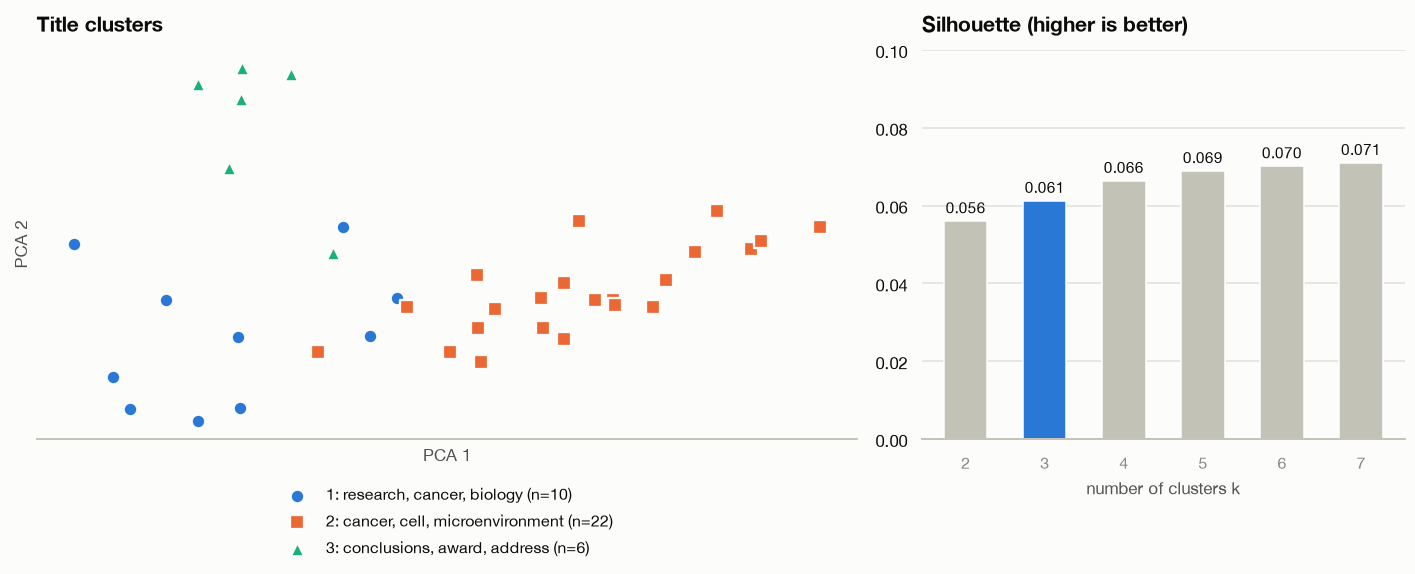

Cluster 1 (research, cancer, biology):
   1. Preclinical Modeling of Breast Cancer in Context and the Lobular Paradigm
  10. The LEAD/DEAL tandem in the cancer research career path
  11. Expanding the Resolution and Scope of Multi‑modal Cancer Research with Innovative Solutions
  14. Resolving Cancer Across Its Biological Layers with Single-Cell and Spatial Biology
  20. From Dark to Detectable -The Cancer Proteogenomics
  22. Introduction of the Mark Foundation for Cancer Research
  32. Patient involvement in cancer research
  33. Opening Keynote Lecture: A Tale of 3 Biomarkers - diagnosis, prognosis and therapy scheduling
  37. Accelerating cancer research with CancerTools: Unlocking discovery with advanced models
  38. Revealing a Deeper View of Cancer with 5D Biology
Cluster 2 (cancer, cell, microenvironment):
   2. Stromal β3-integrin signature predicting recurrence in Oncotype DX low-risk breast cancer
   3. Spatial trajectories of TNBC tumorigenesis reveal orchestrated TME niche

In [6]:
titles = df["title"].tolist()
cluster_report(titles, titles, range(2, 8), "Title clusters", "04_clusters_titles")

## 5. Clusters of title + topics (records with topics)

Each record is embedded as its title followed by its normalized topics, so the topics add the detail the title leaves out.

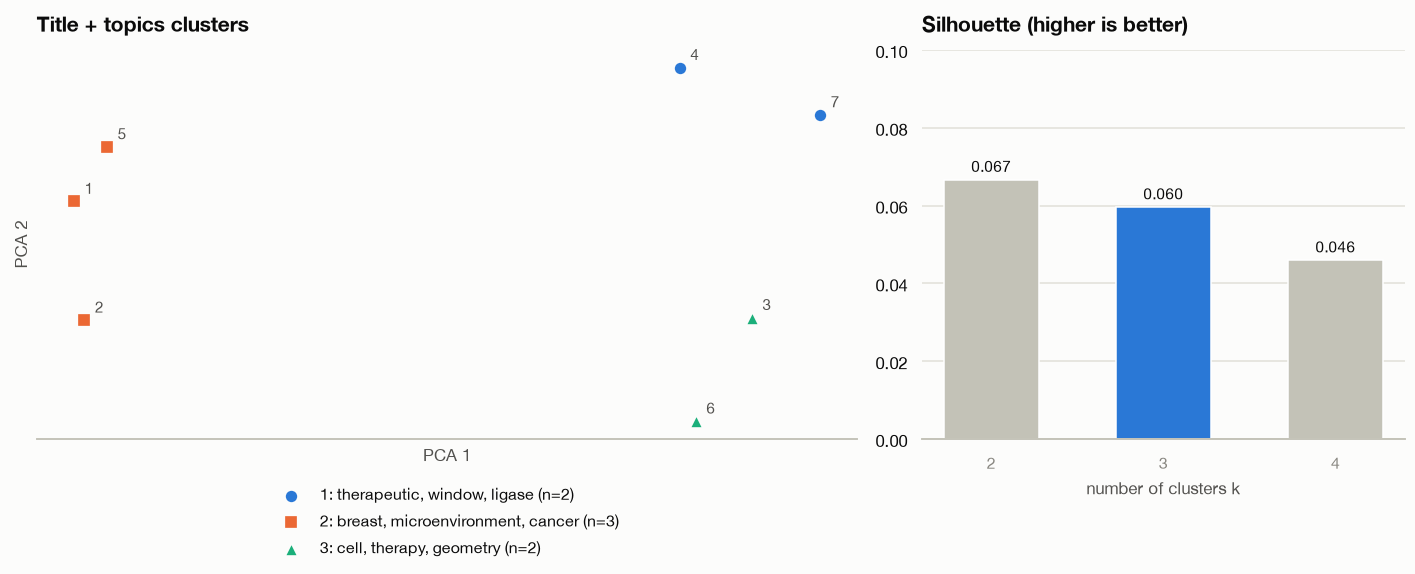

Cluster 1 (therapeutic, window, ligase):
   4. Integration of stress response biology multi-omic datasets decodes prostate cancer dynamic disease …
   7. Protective PROTACs exploit cancer-specific E3 ligase defects to increase the therapeutic window of …
Cluster 2 (breast, microenvironment, cancer):
   1. Stromal β3-integrin signature predicting recurrence in Oncotype DX low-risk breast cancer
   2. Spatial trajectories of TNBC tumorigenesis reveal orchestrated TME niches in time and space
   5. Temporal progression of the liver immune microenvironment during breast cancer metastasis
Cluster 3 (cell, therapy, geometry):
   3. Proffered Paper 8: Intestinal zonation constrains driver mutation selection and shapes tumour evolu…
   6. Simple cell geometry metrics reveal cancer cell diversity and plasticity and guide combination ther…


In [7]:
texts = [
    f"{title}. {'; '.join(map(normalize_topic, topics))}"
    for title, topics in zip(with_topics["title"], with_topics["topics"])
]
cluster_report(
    with_topics["title"].tolist(),
    texts,
    range(2, 5),
    "Title + topics clusters",
    "05_clusters_title_topics",
    number_points=True,
)

How to read the clusters:

- Silhouette scores are close to zero (0.05 to 0.07) in both analyses, so the clusters are weak. In the title clusters the score rises slowly with k and does not single out k=3.
- In the title clusters, cluster 3 mostly holds session logistics (openings, awards, conclusions), but it also pulls in a science title (18, the multiomics data talk), and some logistics titles (10, 22, 32, 33) land in the "research" cluster. The medical embedding model does not separate logistics from science as cleanly as `nomic-embed-text` did in a trial run (all 6 logistics titles in one cluster).
- Seven records are too few to draw conclusions from the title + topics clusters. They show the method works, not what the topics of this conference are.